<div style="text-align: center; background: white; padding: 10px; display: inline-block; width: 100%;">
    <img src="logo_cc.png" width="400">
</div>

# Machine Learning Phase :
After performing Exploratory Data Analysis (EDA) on the original and raw dataset, we obtained a cleaned and more insightful dataset. With this refined data, we will proceed to the machine learning phase, where we will train various models using different techniques and metrics. Special attention will be given to handling the imbalance in our data to ensure fair evaluation. Our goal is to identify the best-performing model based on the chosen metrics.

## Import Python Modules:

First, we need to import the primary modules that will be used in this Project like :
- pandas
- numpy
- Scipy
- Scikit-learn
- keras
- maplotlib
- seaborn
- etc, etc

In [1]:
# Import required packages

# Data packages
import pandas as pd
import numpy as np

# Visualization Packages
from matplotlib import pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn import metrics
from sklearn.metrics import recall_score, make_scorer
from sklearn.model_selection import cross_validate
from sklearn.metrics import roc_curve
from sklearn.metrics import recall_score, confusion_matrix, precision_score, f1_score, accuracy_score, classification_report

## Load Data:

In [8]:
# Load the data
data = pd.read_csv("Ora_Data.csv")

In [9]:
# Data Description
descriptions = pd.read_csv("Ora_Data_Descriptions.csv")
descriptions.style.set_properties(**{'text-align': 'left'})

,Column_Name,Description
0,User_Id,Unique identifier for the user
1,Must_Pay_Monthly_Fee,Boolean indicating if the user must pay a monthly fee
2,Enable_Messages_Notification,Boolean for enabling message notifications
3,Enable_Transactions_Notification,Boolean for enabling transaction notifications
4,num_transactions,Total number of transactions made by the user
5,avg_transaction_amount,Average transaction amount (in DH)
6,transaction_activity_period,Number of days between the first and last transaction
7,num_debit_transactions,Number of debit transactions
8,num_credit_transactions,Number of credit transactions
9,adm_recharge,Count of administrative recharge transactions


## Metrics:
Given the imbalance in our dataset, accuracy may not be a reliable metric as it could be biased towards the majority class. Our primary objective is to prevent churn, which means identifying users who are likely to churn (positive class) is more critical than correctly identifying those who will not churn (negative class). Recall, which measures the proportion of actual positives correctly identified, is therefore a more suitable metric. By focusing on recall, we aim to minimize false negatives, ensuring that we capture as many potential churners as possible for targeted interventions.

## Data Splitting :

### Stratified splitting :

Stratified splitting is essential for our project as it ensures that the class distribution in the target variable is preserved in both the training and testing datasets. Given the imbalance in our dataset, this approach helps us maintain the representativeness of minority and majority classes, enabling fair evaluation of our machine learning models. By doing so, we can better assess the performance of our models and avoid misleading results caused by skewed class distributions. This step is particularly critical for achieving reliable and unbiased outcomes in our classification task.  

In [10]:
X = data.drop(['churn_target','User_Id'], axis=1)
y = data['churn_target']

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size = 0.2, random_state = 42)

In [12]:
# Initialize the model
rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=10,
    class_weight={0: 1, 1: 20}
)

# Define recall scorer
recall_scorer = make_scorer(recall_score)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Calculate recall
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.4f}")

# confusion matrix
confusion = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(confusion)

# classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))


Recall: 0.5731
Confusion Matrix:
[[1211 1259]
 [  73   98]]
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.49      0.65      2470
           1       0.07      0.57      0.13       171

    accuracy                           0.50      2641
   macro avg       0.51      0.53      0.39      2641
weighted avg       0.89      0.50      0.61      2641



C:\Users\USER\AppData\Local\Temp\ipykernel_21476\3968059050.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')


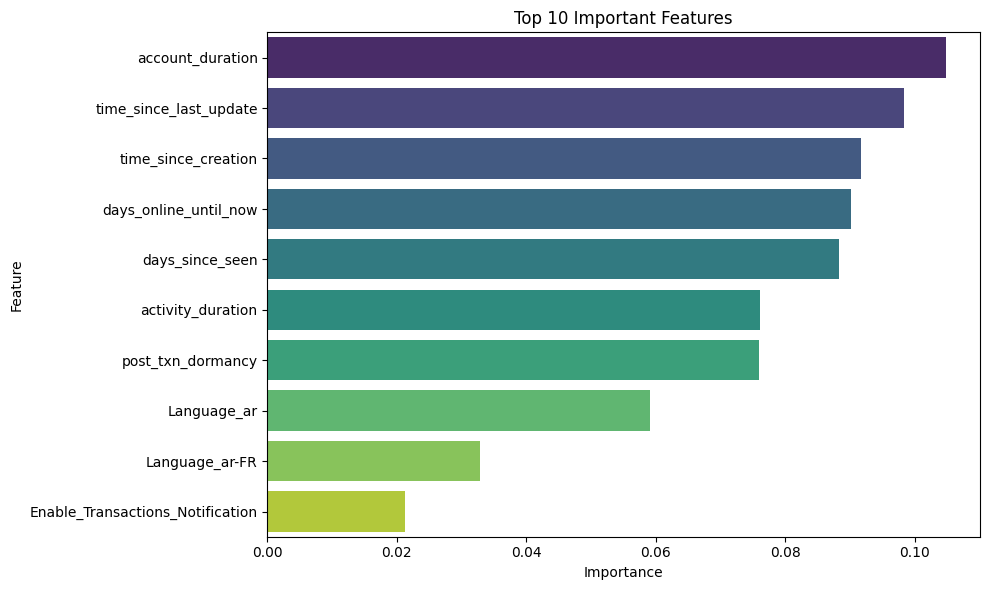

                             Feature  Importance
43                  account_duration    0.104852
32            time_since_last_update    0.098415
30               time_since_creation    0.091685
47             days_online_until_now    0.090100
48                   days_since_seen    0.088318
31                 activity_duration    0.076122
45                 post_txn_dormancy    0.075981
52                       Language_ar    0.059093
53                    Language_ar-FR    0.032910
2   Enable_Transactions_Notification    0.021272


In [13]:
# Extract feature importances from the best model
feature_importances = rf_model.feature_importances_

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Display the top 10 most important features as a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')
plt.title('Top 10 Important Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
print(importance_df.head(10))

### Cross Validation :

Cross-validation is a technique used to evaluate the performance of a model by splitting the dataset into multiple folds. Each fold is used as a testing set while the remaining folds are used for training. This ensures that the model is tested on different subsets of data, providing a more reliable estimate of its performance.


In [14]:

# Initialize the model
rf_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=10,
    class_weight={0: 1, 1: 20}
)

# Define recall scorer
recall_scorer = make_scorer(recall_score)

# Perform cross-validation and keep estimators
cv_results = cross_validate(
    rf_model,
    X,  
    y,
    cv=5,
    scoring={'recall': recall_scorer},
    return_estimator=True  # This keeps the trained models
)

# Get recall scores and corresponding models
recall_scores = cv_results['test_recall']

# Save trained models for further use
trained_models = cv_results['estimator']

# Find the best model (highest recall)
best_model_idx = recall_scores.argmax()
best_model = trained_models[best_model_idx]
best_recall = recall_scores[best_model_idx]

print("All Recall Scores:", recall_scores)
print(f"Best Recall: {best_recall:.2f} (Fold {best_model_idx + 1})")

All Recall Scores: [0.29824561 0.71345029 0.80116959 0.56470588 0.40935673]
Best Recall: 0.80 (Fold 3)


C:\Users\USER\AppData\Local\Temp\ipykernel_21476\4169897055.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')


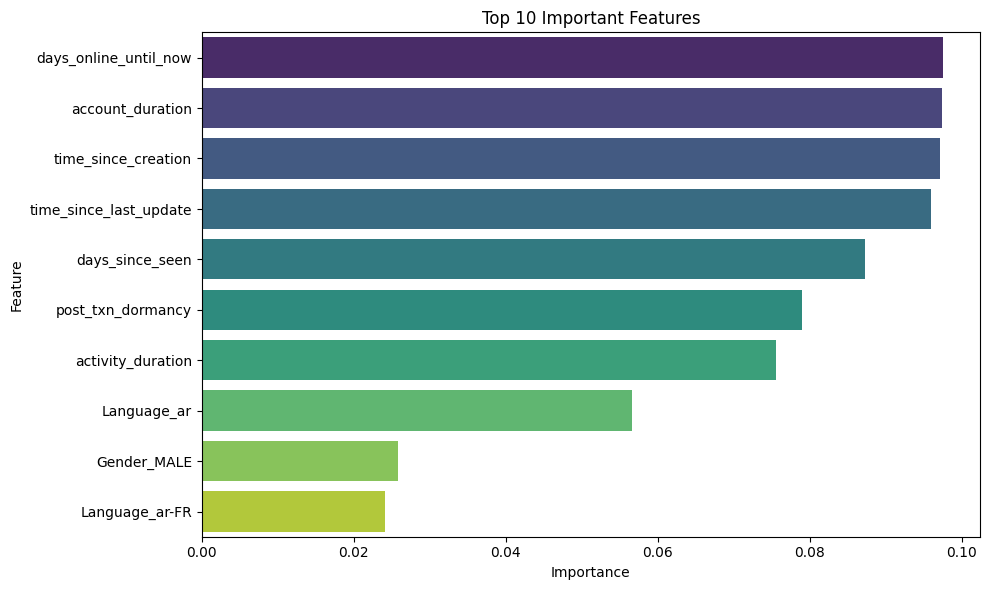

                   Feature  Importance
47   days_online_until_now    0.097519
43        account_duration    0.097342
30     time_since_creation    0.097093
32  time_since_last_update    0.095926
48         days_since_seen    0.087321
45       post_txn_dormancy    0.078944
31       activity_duration    0.075564
52             Language_ar    0.056547
50             Gender_MALE    0.025882
53          Language_ar-FR    0.024100


In [15]:
# Extract feature importances from the best model
feature_importances = best_model.feature_importances_

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Display the top 10 most important features as a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')
plt.title('Top 10 Important Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
print(importance_df.head(10))